# Regresión lineal múltiple: ingreso mensual

Este cuaderno contiene un análisis del modelo de regresión lineal. El objetivo es describir y predecir `ingreso_mensual` usando `anos_educacion` y `experiencia`. Una regresión múltiple estima el aporte promedio asociado a cada predictor manteniendo constantes los demás. Una asociación no demuestra causalidad.

**Datos**. `datos.xlsx` tiene 800 personas ocupadas simuladas con fines didácticos, al estilo de la Gran Encuesta Integrada de Hogares (GEIH): edad, educación, experiencia, horas, formalidad, sexo, zona, sector, estrato e ingreso laboral mensual. El ingreso se generó con una ecuación de Mincer conocida, así que se puede comprobar si la regresión recupera los efectos «verdaderos».

## Preparación


In [1]:
"""Regresión lineal múltiple para explicar ingreso_mensual."""

# Compruebe e instale dependencias antes de importar las bibliotecas del análisis.
import importlib.util
import sys

DEPENDENCIAS = {
    "pandas": "pandas",
    "numpy": "numpy",
    "scikit-learn": "sklearn",
    "statsmodels": "statsmodels",
    "matplotlib": "matplotlib",
    "openpyxl": "openpyxl",
}
faltantes = [paquete for paquete, modulo in DEPENDENCIAS.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    print("Instalando dependencias faltantes:", ", ".join(faltantes))
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", *faltantes], check=True)
else:
    print("Todas las dependencias requeridas ya están instaladas.")
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")

# Importe las bibliotecas una vez verificadas las dependencias.
from pathlib import Path
import shutil
import warnings

import matplotlib
# Se comenta 'Agg' para permitir que los gráficos se rendericen e incrusten dentro de VS Code / Jupyter Notebook
# matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# Defina las rutas relativas al archivo y cree las carpetas del proyecto.
BASE_DIR = Path(__file__).resolve().parent if '__file__' in locals() else Path(".").resolve()
DATOS_DIR = BASE_DIR / "datos"
RESULTADOS_DIR = BASE_DIR / "resultados"
FIGURAS_DIR = BASE_DIR / "visualizaciones"
for carpeta in (DATOS_DIR, RESULTADOS_DIR, FIGURAS_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)

ARCHIVO_DATOS = DATOS_DIR / "datos.xlsx"
ARCHIVO_ORIGINAL = BASE_DIR / "datos.xlsx"
if not ARCHIVO_DATOS.exists() and ARCHIVO_ORIGINAL.exists():
    shutil.copy2(ARCHIVO_ORIGINAL, ARCHIVO_DATOS)
    print(f"Se copió el archivo de entrada a: {ARCHIVO_DATOS}")
if not ARCHIVO_DATOS.exists():
    raise FileNotFoundError(
        f"No se encontró {ARCHIVO_DATOS}. Coloque allí datos.xlsx (hoja trabajadores)."
    )

HOJA_DATOS = "trabajadores"
Y = "ingreso_mensual"
X_SOLICITADAS = ["anos_educacion", "experiencia"]
ARCHIVO_EXCEL = RESULTADOS_DIR / "regresion_lineal_resultados.xlsx"
tablas = {}


Todas las dependencias requeridas ya están instaladas.


## Paso 1. Cargar y revisar los datos

Pandas abre la hoja `trabajadores`. Se muestran una muestra de filas, los tipos de columna y los valores faltantes; además se prepara una tabla con tamaño, estadísticas y frecuencias para la hoja `descripcion`. El código conserva únicamente la respuesta y las dos X pedidas para el modelo y excluye filas incompletas en esas columnas. También deja listos los predictores. Si alguna X es texto, `OneHotEncoder` la convierte en indicadores 0/1 y omite una categoría como referencia; así los coeficientes de las otras categorías se interpretan en comparación con esa referencia.

In [2]:
print("\nPASO 1. Carga y revisión de datos")
datos = pd.read_excel(ARCHIVO_DATOS, sheet_name=HOJA_DATOS, engine="openpyxl")
faltan_columnas = [c for c in [Y, *X_SOLICITADAS] if c not in datos.columns]
if faltan_columnas:
    raise ValueError(f"Faltan columnas requeridas en {HOJA_DATOS}: {faltan_columnas}")
print(f"Archivo: {ARCHIVO_DATOS}\nHoja: {HOJA_DATOS}\nTamaño: {datos.shape[0]} filas × {datos.shape[1]} columnas")
print("Primeras cinco filas:\n", datos.head().to_string(index=False))
print("Tipos de columnas:\n", datos.dtypes.astype(str).to_string())
print("Faltantes por columna:\n", datos.isna().sum().to_string())
descripcion = pd.DataFrame({
    "elemento": ["filas", "columnas", "nombres_columnas", "tipos", "faltantes_por_columna",
                 "estadisticas_numericas", "frecuencias_categoricas", "primeras_5_filas"],
    "detalle": [
        str(len(datos)), str(datos.shape[1]), ", ".join(map(str, datos.columns)),
        datos.dtypes.astype(str).to_dict(), datos.isna().sum().to_dict(),
        datos.describe().to_dict(),
        {c: datos[c].value_counts(dropna=False).to_dict() for c in datos.select_dtypes(exclude=np.number).columns},
        datos.head().to_dict(orient="records"),
    ],
})
tablas["descripcion"] = descripcion

# Prepare únicamente las columnas elegidas y retire filas incompletas en el modelo.
modelo_datos = datos[[Y, *X_SOLICITADAS]].copy()
antes = len(modelo_datos)
modelo_datos = modelo_datos.dropna(subset=[Y, *X_SOLICITADAS]).reset_index(drop=True)
if len(modelo_datos) < antes:
    print(f"Se excluyeron {antes - len(modelo_datos)} filas con faltantes en las variables del modelo.")
if len(modelo_datos) < 5:
    raise ValueError("Se necesitan al menos cinco filas completas para ajustar y evaluar el modelo.")
for x in X_SOLICITADAS:
    if not pd.api.types.is_numeric_dtype(modelo_datos[x]) and modelo_datos[x].nunique() > 20:
        raise ValueError(f"La columna categórica {x} tiene más de 20 categorías; revise su codificación.")

# Convierta predictores de texto en indicadores y registre las categorías de referencia.
variables_numericas = [x for x in X_SOLICITADAS if pd.api.types.is_numeric_dtype(modelo_datos[x])]
variables_categoricas = [x for x in X_SOLICITADAS if x not in variables_numericas]
referencias = {}
if variables_categoricas:
    try:
        encoder = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(drop="first", handle_unknown="ignore", sparse=False)
    codificadas = encoder.fit_transform(modelo_datos[variables_categoricas].astype(str))
    nombres_codificados = encoder.get_feature_names_out(variables_categoricas).tolist()
    referencias = {col: str(categorias[0]) for col, categorias in zip(variables_categoricas, encoder.categories_)}
    X_categoricas = pd.DataFrame(codificadas, columns=nombres_codificados, index=modelo_datos.index)
    print("Variables categóricas convertidas a columnas 0/1:", nombres_codificados)
    print("Categorías de referencia (omitidas):", referencias)
else:
    X_categoricas = pd.DataFrame(index=modelo_datos.index)
    print("Las dos variables X son numéricas; no se requiere codificación categórica.")
X = pd.concat([modelo_datos[variables_numericas].astype(float), X_categoricas], axis=1)
if X.shape[1] == 0:
    raise ValueError("No quedaron predictores para el modelo.")
y = modelo_datos[Y].astype(float)



PASO 1. Carga y revisión de datos
Archivo: L:\IA para la investigación\Machine_learning\1. Regresion lineal\datos\datos.xlsx
Hoja: trabajadores
Tamaño: 800 filas × 13 columnas
Primeras cinco filas:
  id_persona   ciudad   zona   sexo  edad  anos_educacion nivel_educativo  experiencia  horas_semana formal       sector  estrato  ingreso_mensual
          1 Medellín Urbana Hombre    43              12         Técnico           25            52     Sí    Servicios        5          3075000
          2   Bogotá Urbana  Mujer    33              10    Bachillerato           17            63     No    Servicios        4          1274000
          3   Bogotá Urbana Hombre    31              13         Técnico           12            41     Sí     Comercio        4          1554000
          4     Cali  Rural Hombre    44              11    Bachillerato           27            34     Sí    Servicios        4          1746000
          5 Medellín Urbana  Mujer    49               3        Primar

## Paso 2. Dispersión de ingreso y predictores

El diagrama de dispersión dibuja cada predictor frente al ingreso. Permite ver si la relación parece crecer, disminuir, curvarse o tener puntos alejados. La figura se guarda como PNG a 150 dpi y se visualiza dentro del entorno de VS Code.


PASO 2. Diagramas de dispersión con líneas de tendencia


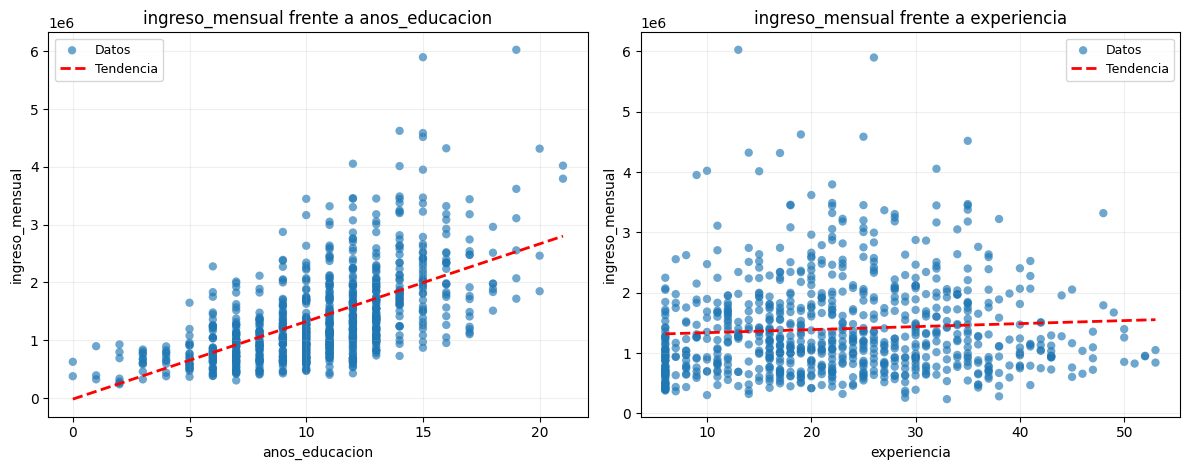

Se guardó visualizaciones/01_dispersion.png con líneas de tendencia.


In [12]:
print("\nPASO 2. Diagramas de dispersión con líneas de tendencia")
fig, ejes = plt.subplots(1, len(X_SOLICITADAS), figsize=(6 * len(X_SOLICITADAS), 4.8))
ejes = np.atleast_1d(ejes)

for ax, xcol in zip(ejes, X_SOLICITADAS):
    if pd.api.types.is_numeric_dtype(modelo_datos[xcol]):
        x_valores = modelo_datos[xcol].to_numpy()
        y_valores = modelo_datos[Y].to_numpy()
        
        ax.scatter(x_valores, y_valores, alpha=0.65, edgecolor="none", label="Datos")
        ax.set_xlabel(xcol)
    else:
        categorias = sorted(modelo_datos[xcol].astype(str).unique())
        mapa = {cat: i for i, cat in enumerate(categorias)}
        x_valores = modelo_datos[xcol].astype(str).map(mapa).to_numpy()
        y_valores = modelo_datos[Y].to_numpy()
        
        ax.scatter(x_valores, y_valores, alpha=0.6, label="Datos")
        ax.set_xticks(range(len(categorias)), categorias, rotation=30, ha="right")
        ax.set_xlabel(f"{xcol} (categorías)")
    
    # Calcular y dibujar la línea de tendencia si hay suficientes datos
    if len(x_valores) > 1:
        m, b = np.polyfit(x_valores, y_valores, 1)
        x_linea = np.linspace(x_valores.min(), x_valores.max(), 100)
        ax.plot(x_linea, m * x_linea + b, color="red", linestyle="--", linewidth=2, label="Tendencia")
        ax.legend(fontsize=9)

    ax.set_ylabel(Y)
    ax.set_title(f"{Y} frente a {xcol}")
    ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(FIGURAS_DIR / "01_dispersion.png", dpi=150, bbox_inches="tight")
plt.show()
print("Se guardó visualizaciones/01_dispersion.png con líneas de tendencia.")



## Paso 3. Leer la codificación

El conjunto actual tiene dos X numéricas, por lo que no necesita columnas indicadoras ni categorías de referencia. Si cambia una X por una variable categórica, el script imprimirá qué niveles creó y cuál dejó como categoría base.

In [4]:
print("\nPASO 3. Preparación de predictores")
print(f"Variables numéricas: {variables_numericas or 'ninguna'}")
print(f"Categorías omitidas como referencia: {referencias or 'no aplica'}")



PASO 3. Preparación de predictores
Variables numéricas: ['anos_educacion', 'experiencia']
Categorías omitidas como referencia: no aplica


## Paso 4. Separar entrenamiento y prueba

Se reservan 80 % de las filas para entrenar el modelo y 20 % para evaluar predicciones en datos no usados al ajustarlo. `random_state=42` fija la selección para que se pueda reproducir. Esta separación ayuda a estimar cómo podría funcionar el modelo en observaciones nuevas.

In [5]:
print("\nPASO 4. División entrenamiento/prueba")
indices = np.arange(len(modelo_datos))
idx_train, idx_test = train_test_split(indices, test_size=0.20, random_state=42)
X_train, X_test = X.iloc[idx_train].copy(), X.iloc[idx_test].copy()
y_train, y_test = y.iloc[idx_train].copy(), y.iloc[idx_test].copy()
print(f"Entrenamiento: {len(idx_train)} filas (80 %); prueba: {len(idx_test)} filas (20 %). random_state=42.")



PASO 4. División entrenamiento/prueba
Entrenamiento: 640 filas (80 %); prueba: 160 filas (20 %). random_state=42.


## Paso 5. Ajustar e interpretar coeficientes

Scikit-learn ajusta la regresión que se usará para predecir. Statsmodels ajusta el mismo modelo en entrenamiento para calcular intervalos de confianza del 95 % y valores p. La ecuación muestra la predicción estimada. Cada beta de una X indica cuánto cambia en promedio el ingreso al aumentar esa X en una unidad, manteniendo las demás X fijas; el intercepto representa el valor matemático cuando las X valen cero, aunque ese caso podría no tener sentido práctico.

In [6]:
print("\nPASO 5. Ajuste con scikit-learn y statsmodels")
modelo_sklearn = LinearRegression().fit(X_train, y_train)
modelo_stats = sm.OLS(y_train, sm.add_constant(X_train, has_constant="add")).fit()
beta = modelo_stats.params
intervalos = modelo_stats.conf_int(alpha=0.05)
coeficientes = pd.DataFrame({
    "variable": beta.index,
    "beta": beta.values,
    "IC95_inferior": intervalos.iloc[:, 0].values,
    "IC95_superior": intervalos.iloc[:, 1].values,
    "valor_p": modelo_stats.pvalues.values,
})
coeficientes["interpretacion"] = coeficientes["variable"].map(
    lambda v: ("Intercepto: valor estimado de ingreso_mensual cuando todos los predictores valen cero."
               if v == "const" else
               f"Si {v} sube en 1 unidad, ingreso_mensual cambia en promedio {beta[v]:,.2f} unidades, "
               "con las demás X fijas."))
ecuacion = f"ingreso_mensual = {beta['const']:,.2f}" + "".join(
    [f" {'+' if beta[v] >= 0 else '-'} {abs(beta[v]):,.2f}×{v}" for v in X_train.columns]
)
print("Ecuación estimada:\n", ecuacion)
print("Coeficientes e inferencia (IC de 95 % y p):\n", coeficientes.to_string(index=False))
print("Nota: los intervalos y valores p son inferencia OLS del conjunto de entrenamiento.")
tablas["coeficientes"] = coeficientes
tablas["ecuacion"] = pd.DataFrame({"elemento": ["ecuacion_estimada", "n_entrenamiento", "metodo"],
                                   "valor": [ecuacion, len(idx_train), "OLS de statsmodels; predictores ajustados con scikit-learn"]})



PASO 5. Ajuste con scikit-learn y statsmodels
Ecuación estimada:
 ingreso_mensual = -440,351.57 + 145,209.09×anos_educacion + 13,718.72×experiencia
Coeficientes e inferencia (IC de 95 % y p):
       variable           beta  IC95_inferior  IC95_superior      valor_p                                                                                                     interpretacion
         const -440351.574421 -654155.247519 -226547.901323 5.887935e-05                             Intercepto: valor estimado de ingreso_mensual cuando todos los predictores valen cero.
anos_educacion  145209.087999  130701.250494  159716.925503 1.386466e-67 Si anos_educacion sube en 1 unidad, ingreso_mensual cambia en promedio 145,209.09 unidades, con las demás X fijas.
   experiencia   13718.717789    8952.397820   18485.037757 2.393495e-08     Si experiencia sube en 1 unidad, ingreso_mensual cambia en promedio 13,718.72 unidades, con las demás X fijas.
Nota: los intervalos y valores p son inferencia OLS de

## Paso 6. Comparar valores reales y predichos

En prueba, cada punto compara el ingreso observado con la predicción. La línea de 45 grados representa predicción perfecta; los puntos más cerca de ella tienen errores menores. Como ambas X son numéricas, también se dibuja el plano estimado en 3D junto a las observaciones.


PASO 6. Valores reales frente a predichos


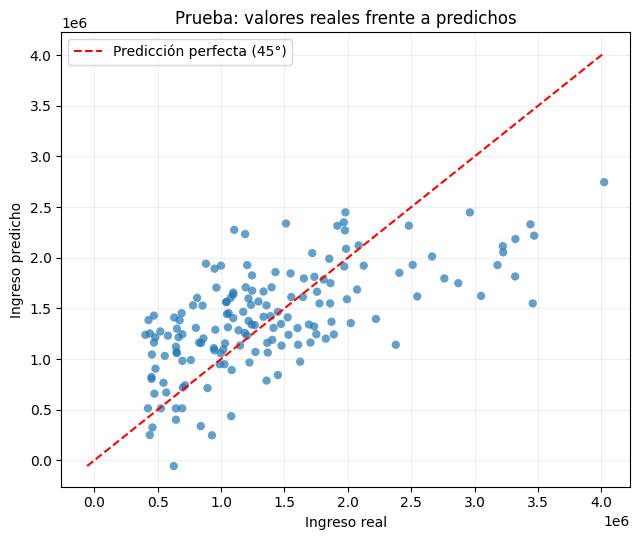

Se guardó visualizaciones/02_ajuste.png.


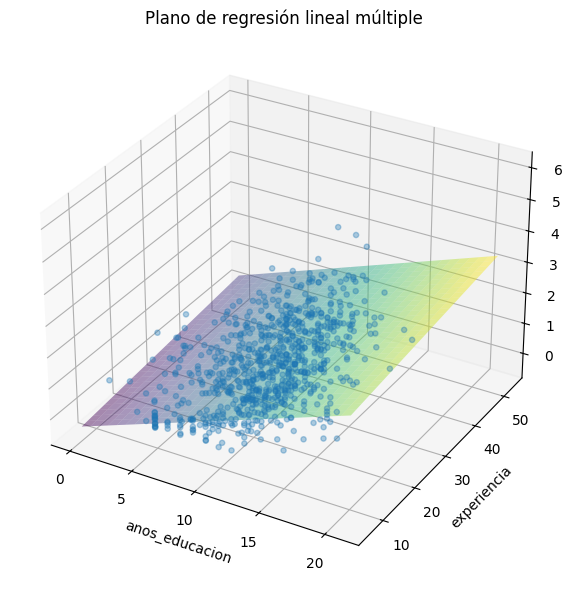

Se guardó visualizaciones/03_plano_3d.png.


In [7]:
print("\nPASO 6. Valores reales frente a predichos")
yhat_train = modelo_sklearn.predict(X_train)
yhat_test = modelo_sklearn.predict(X_test)
predicciones = pd.DataFrame({"valor_real": y_test.values, "predicho": yhat_test})
predicciones["residuo"] = predicciones["valor_real"] - predicciones["predicho"]
limite = max(float(y_test.max()), float(np.max(yhat_test)), float(y_test.min()), float(np.min(yhat_test)))
minimo = min(float(y_test.min()), float(np.min(yhat_test)))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(y_test, yhat_test, alpha=0.7, edgecolor="none")
ax.plot([minimo, limite], [minimo, limite], "r--", label="Predicción perfecta (45°)")
ax.set(xlabel="Ingreso real", ylabel="Ingreso predicho", title="Prueba: valores reales frente a predichos")
ax.legend(); ax.grid(alpha=0.2); fig.tight_layout()
fig.savefig(FIGURAS_DIR / "02_ajuste.png", dpi=150, bbox_inches="tight")
plt.show()
print("Se guardó visualizaciones/02_ajuste.png.")

if len(variables_numericas) == 2 and not variables_categoricas:
    x1, x2 = X_SOLICITADAS
    xx, yy = np.meshgrid(np.linspace(modelo_datos[x1].min(), modelo_datos[x1].max(), 30),
                         np.linspace(modelo_datos[x2].min(), modelo_datos[x2].max(), 30))
    malla = pd.DataFrame({x1: xx.ravel(), x2: yy.ravel()})[X_train.columns]
    zz = modelo_sklearn.predict(malla).reshape(xx.shape)
    fig = plt.figure(figsize=(8, 6)); ax = fig.add_subplot(111, projection="3d")
    ax.scatter(modelo_datos[x1], modelo_datos[x2], y, alpha=0.35, s=14, label="Observaciones")
    ax.plot_surface(xx, yy, zz, alpha=0.45, cmap="viridis", linewidth=0)
    ax.set(xlabel=x1, ylabel=x2, zlabel=Y, title="Plano de regresión lineal múltiple")
    fig.tight_layout(); fig.savefig(FIGURAS_DIR / "03_plano_3d.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Se guardó visualizaciones/03_plano_3d.png.")
else:
    print("No se creó el plano 3D: se requiere que las dos X sean numéricas.")


## Paso 7. Inspeccionar los residuos

Un residuo es el valor real menos el predicho. Idealmente, los puntos del gráfico fluctúan alrededor de cero sin forma clara y con una dispersión parecida en todo el eje horizontal. Una curva u ola sugiere que una recta no captura el patrón; un embudo sugiere varianza no constante; una cola marcada en el histograma puede indicar asimetría o valores extremos. Las reglas del script dan una alerta orientativa, que debe confirmarse visualmente. Si aparecen estos patrones, revise transformaciones o formas no lineales, valores extremos y errores estándar robustos antes de hacer inferencia.


PASO 7. Revisión de residuos


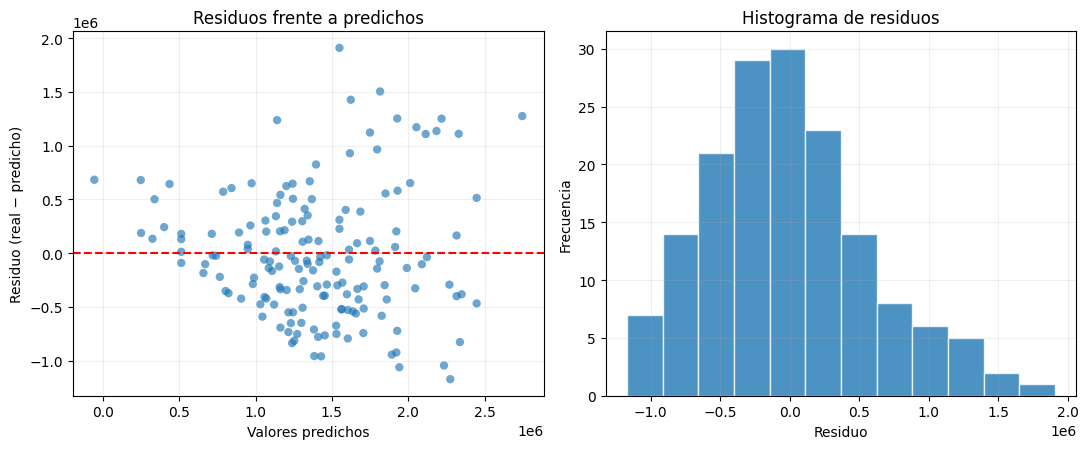

Se guardó visualizaciones/04_residuos.png.
Diagnóstico orientativo: En prueba se observan posible curva/ola (las medias por tercios suben y bajan), posible embudo (la dispersión por tercios cambia 1.8 veces), posible cola larga hacia la derecha en el histograma. La linealidad puede fallar; revise formas no lineales e interacciones y compare alternativas; la varianza constante puede fallar; considere errores estándar robustos y transformaciones de y; la normalidad de los residuos puede fallar; revise observaciones extremas y use inferencia robusta si procede.


In [8]:
print("\nPASO 7. Revisión de residuos")
residuos = predicciones["residuo"].to_numpy()
pred = predicciones["predicho"].to_numpy()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6))
ax1.scatter(pred, residuos, alpha=0.65, edgecolor="none"); ax1.axhline(0, color="red", linestyle="--")
ax1.set(xlabel="Valores predichos", ylabel="Residuo (real − predicho)", title="Residuos frente a predichos"); ax1.grid(alpha=0.2)
ax2.hist(residuos, bins="auto", edgecolor="white", alpha=0.8)
ax2.set(xlabel="Residuo", ylabel="Frecuencia", title="Histograma de residuos"); ax2.grid(alpha=0.2)
fig.tight_layout(); fig.savefig(FIGURAS_DIR / "04_residuos.png", dpi=150, bbox_inches="tight")
plt.show()

orden_pred = np.argsort(pred)
tercios_indice = np.array_split(orden_pred, 3)
medias_tercios = [float(np.mean(residuos[g])) for g in tercios_indice if len(g)]
desvios_tercios = [float(np.std(residuos[g], ddof=1)) for g in tercios_indice if len(g) > 1]
curva = len(medias_tercios) == 3 and ((medias_tercios[1] > medias_tercios[0] and medias_tercios[1] > medias_tercios[2]) or
                                     (medias_tercios[1] < medias_tercios[0] and medias_tercios[1] < medias_tercios[2]))
razon_dispersion = max(desvios_tercios) / max(min(desvios_tercios), 1e-9) if desvios_tercios else 1.0
embudo = razon_dispersion >= 1.5
asimetria = float(pd.Series(residuos).skew()) if len(residuos) > 2 else 0.0
colas = abs(asimetria) >= 0.5
hallazgos = []
if curva: hallazgos.append("posible curva/ola (las medias por tercios suben y bajan)")
if embudo: hallazgos.append(f"posible embudo (la dispersión por tercios cambia {razon_dispersion:.1f} veces)")
if colas: hallazgos.append("posible cola larga hacia " + ("la derecha" if asimetria > 0 else "la izquierda") + " en el histograma")
if not hallazgos: hallazgos.append("no se detectan patrones fuertes con estas reglas sencillas; confirme visualmente")
acciones = []
if curva: acciones.append("la linealidad puede fallar; revise formas no lineales e interacciones y compare alternativas")
if embudo: acciones.append("la varianza constante puede fallar; considere errores estándar robustos y transformaciones de Y")
if colas: acciones.append("la normalidad de los residuos puede fallar; revise observaciones extremas y use inferencia robusta si procede")
decision = ("; ".join(acciones).capitalize() + "." if acciones else
            "No hay señal clara de incumplimiento en estos gráficos; mantenga cautela y revise supuestos supuestos.")
diagnostico = f"En prueba se observan {', '.join(hallazgos)}. {decision}"
print("Se guardó visualizaciones/04_residuos.png.")
print("Diagnóstico orientativo:", diagnostico)


## Paso 8. Medir desempeño y comparar con una referencia

El MAE es el tamaño promedio del error absoluto y conserva las unidades del ingreso; más bajo es mejor. R² resume qué proporción de variación representa el modelo; más alto es mejor, y en prueba puede ser negativo. La línea base predice siempre el promedio del ingreso de entrenamiento. Si el modelo supera esta referencia, aporta capacidad predictiva frente a usar solamente ese promedio. Una diferencia grande entre desempeño de entrenamiento y prueba puede indicar sobreajuste; el script marca como alerta una brecha de R² superior a 0,15.


PASO 8. Métricas y línea base
MAE está en las unidades de ingreso; R² es la proporción de variación explicada (puede ser negativo en prueba).
     conjunto                            metodo        MAE      R2
entrenamiento                  regresion_lineal 458,954.94  0.3781
entrenamiento linea_base_promedio_entrenamiento 605,411.05  0.0000
       prueba                  regresion_lineal 462,711.68  0.4161
       prueba linea_base_promedio_entrenamiento 595,700.12 -0.0010
Brecha R² entrenamiento menos prueba: -0.0380. No hay evidencia fuerte de sobreajuste según la brecha de R² (>0.15); compare también los MAE y el contexto.
Línea base: si el modelo mejora sobre ella, aporta capacidad predictiva frente a usar solo el promedio.


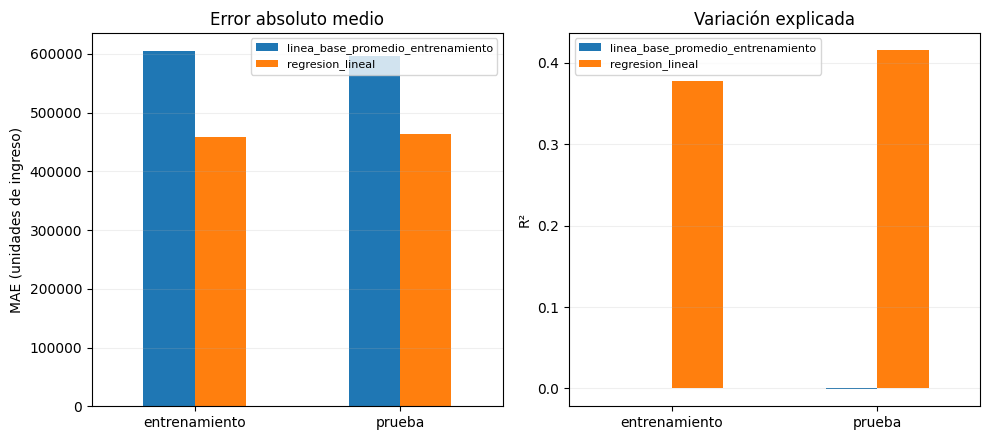

Se guardó visualizaciones/05_metricas.png.


In [9]:
print("\nPASO 8. Métricas y línea base")
promedio_train = float(y_train.mean())
metricas = []
for nombre, real, pred_modelo in [("entrenamiento", y_train, yhat_train), ("prueba", y_test, yhat_test)]:
    baseline = np.full(len(real), promedio_train)
    metricas.extend([
        {"conjunto": nombre, "metodo": "regresion_lineal", "MAE": mean_absolute_error(real, pred_modelo), "R2": r2_score(real, pred_modelo)},
        {"conjunto": nombre, "metodo": "linea_base_promedio_entrenamiento", "MAE": mean_absolute_error(real, baseline), "R2": r2_score(real, baseline)},
    ])
metricas = pd.DataFrame(metricas)
print("MAE está en las unidades de ingreso; R² es la proporción de variación explicada (puede ser negativo en prueba).")
print(metricas.to_string(index=False, formatters={"MAE": "{:,.2f}".format, "R2": "{:.4f}".format}))
mt = metricas.set_index(["conjunto", "metodo"])
train_r2 = float(mt.loc[("entrenamiento", "regresion_lineal"), "R2"])
test_r2 = float(mt.loc[("prueba", "regresion_lineal"), "R2"])
train_mae = float(mt.loc[("entrenamiento", "regresion_lineal"), "MAE"])
test_mae = float(mt.loc[("prueba", "regresion_lineal"), "MAE"])
brecha_r2 = train_r2 - test_r2
sobreajuste = brecha_r2 > 0.15 and test_r2 < train_r2
juicio_ajuste = ("Hay señal de posible sobreajuste: el R² de entrenamiento supera al de prueba por más de 0.15."
                 if sobreajuste else
                 "No hay evidencia fuerte de sobreajuste según la brecha de R² (>0.15); compare también los MAE y el contexto.")
print(f"Brecha R² entrenamiento menos prueba: {brecha_r2:.4f}. {juicio_ajuste}")
print("Línea base: si el modelo mejora sobre ella, aporta capacidad predictiva frente a usar solo el promedio.")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))
orden = ["entrenamiento", "prueba"]
for ax, medida, titulo, ylabel in [(ax1, "MAE", "Error absoluto medio", "MAE (unidades de ingreso)"),
                                   (ax2, "R2", "Variación explicada", "R²")]:
    piv = metricas.pivot(index="conjunto", columns="metodo", values=medida).reindex(orden)
    piv.plot(kind="bar", ax=ax, rot=0)
    ax.set(title=titulo, xlabel="", ylabel=ylabel); ax.grid(axis="y", alpha=0.2); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGURAS_DIR / "05_metricas.png", dpi=150, bbox_inches="tight")
plt.show()
print("Se guardó visualizaciones/05_metricas.png.")
tablas["metricas"] = metricas


## Paso 9. Guardar predicciones y resumir

La tabla `predicciones` conserva para cada fila de prueba el ingreso real, el predicho y el residuo. El último bloque escribe todas las tablas en un solo libro Excel, una por hoja, y construye `resumen` con ecuación, métricas y diagnóstico. Las cinco figuras se guardan en `visualizaciones/` y se muestran en el notebook.

In [10]:
print("\nPASO 9. Predicciones de prueba")
predicciones.insert(0, "indice_fila_datos", idx_test)
print(f"Se guardan {len(predicciones)} predicciones de prueba; primeras cinco:\n", predicciones.head().to_string(index=False))
tablas["predicciones"] = predicciones

print("\nCreación del resumen y del libro de Excel")
resumen = pd.DataFrame({
    "indicador": ["filas_totales", "filas_modelo", "n_entrenamiento", "n_prueba", "predictores", "categorias_referencia",
                  "ecuacion_estimada", "MAE_entrenamiento", "R2_entrenamiento", "MAE_prueba", "R2_prueba",
                  "MAE_prueba_linea_base", "R2_prueba_linea_base", "diagnostico_residuos", "revision_sobreajuste"],
    "valor": [len(datos), len(modelo_datos), len(idx_train), len(idx_test), ", ".join(X.columns), str(referencias), ecuacion,
              train_mae, train_r2, test_mae, test_r2,
              float(mt.loc[("prueba", "linea_base_promedio_entrenamiento"), "MAE"]),
              float(mt.loc[("prueba", "linea_base_promedio_entrenamiento"), "R2"]), diagnostico, juicio_ajuste],
})
tablas["resumen"] = resumen
with pd.ExcelWriter(ARCHIVO_EXCEL, engine="openpyxl") as writer:
    for nombre, tabla in tablas.items():
        tabla.to_excel(writer, sheet_name=nombre[:31], index=False)
print(f"Se guardó el libro con hojas {', '.join(tablas)} en: {ARCHIVO_EXCEL}")
print("\nAnálisis terminado. Revise resultados/regresion_lineal_resultados.xlsx y visualizaciones/.")



PASO 9. Predicciones de prueba
Se guardan 160 predicciones de prueba; primeras cinco:
  indice_fila_datos  valor_real     predicho        residuo
               696   2085000.0 2.121909e+06  -36908.843635
               667   1757000.0 1.664541e+06   92459.048262
                63   1054000.0 1.313551e+06 -259551.096912
               533    840000.0 3.382436e+05  501756.365712
                66    482000.0 1.215195e+06 -733194.969954

Creación del resumen y del libro de Excel
Se guardó el libro con hojas descripcion, coeficientes, ecuacion, metricas, predicciones, resumen en: L:\IA para la investigación\Machine_learning\1. Regresion lineal\resultados\regresion_lineal_resultados.xlsx

Análisis terminado. Revise resultados/regresion_lineal_resultados.xlsx y visualizaciones/.
